# Entrega I - Proyecto de Redes Neuronales para Datos Secuenciales
## Análisis de Sentimientos a Partir de un Dataset de Tweets Relacionados con Aerolíneas Estadounidenses

### Integrantes
| Nombre | Código |
|-----------------|--------|
| Juliana Melissa Bolaños Araujo | 2372224 |
| Lenin Esteban Carabalí Moreno | 2310025 |
| Christian David Vargas Gutiérrez| 2179172 |

Universidad del Valle  
Escuela de Ingeniería de Sistemas y Computación  
Octubre 2026

---

### Descripción

En este Notebook se desarrolla la primera entrega del proyecto práctico de la asignatura de **Redes Neuronales para Datos Secuenciales**. El objetivo es entrenar y evaluar distintas variantes de una arquitectura de **Perceptrón Multicapa (MLP)** para la clasificación de textos relacionados con aerolíneas estadounidenses. En particular, se busca predecir el sentimiento expresado por los usuarios (**positivo, negativo o neutral**) a partir de un conjunto de datos de tweets.

### Dataset

**Nombre:** Twitter US Airline Sentiment

**Fuente:** [Kaggle](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) 

**Clases:** positivo, negativo, neutral

**Total de Tweets:** 14,640

---

### Estructura del notebook

| Sección | Contenido |
|---------|-----------|
| 1 | Configuración del Entorno y Descarga del Dataset |
| 2 | Preprocesamiento del Dataset y Análisis Exploratorio de Datos |
| 4 | Preprocesamiento del Texto y Vectorización de Tweets |

## 1. Configuración del Entorno y Descarga del Dataset

In [22]:
# Instalación de librerías necesarias
!pip install -q numpy pandas matplotlib seaborn tensorflow keras keras-tuner kagglehub scikit-learn

In [23]:
# Importar librerías necesarias
import os, random, kagglehub
import tensorflow, keras, keras_tuner
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

SEED = 24
MORADO = "#4b006e"
AZUL = "#069af3"
VERDE = "#12e193"

In [3]:
# Descarga del dataset desde Kaggle
path_to_dataset = kagglehub.dataset_download('crowdflower/twitter-airline-sentiment')
print(f"Dataset descargado en: {path_to_dataset}\n")
print(f"Archivos en el dataset: {os.listdir(path_to_dataset)}")

Dataset descargado en: C:\Users\ChristianV\.cache\kagglehub\datasets\crowdflower\twitter-airline-sentiment\versions\4

Archivos en el dataset: ['database.sqlite', 'Tweets.csv']


In [4]:
# Carga del dataset en un DataFrame de Pandas
data = pd.read_csv(os.path.join(path_to_dataset, 'Tweets.csv'))

data.head(5)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 2. Preprocesamiento del Dataset y Análisis Exploratorio de Datos

Empezamos por revisar las características del dataset, para entender mejor la información que contiene y cuáles son las variables relevantes para el análisis de sentimientos.

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

El dataset contiene **14,640 registros y 15 columnas**. De entrada vemos que hay columnas que no son tan relevantes para el **análisis de sentimientos a partir de texto**, como lo son el ID del tweet `tweet_id`, el nombre del usuario que publicó el tweet `name`, la cantidad de retweets `retweet_count`, la fecha de publicación del tweet `tweet_created`, las coordenadas geográficas `tweet_coord`, la ubicación geográfica `tweet_location` y la zona horaria del usuario `user_timezone`. Así que procedemos a eliminar estas columnas.

In [6]:
data.drop(columns=['tweet_id', 'name', 'retweet_count', 'tweet_created', 'tweet_coord', 'tweet_location', 'user_timezone'], inplace=True)

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             14640 non-null  str    
 1   airline_sentiment_confidence  14640 non-null  float64
 2   negativereason                9178 non-null   str    
 3   negativereason_confidence     10522 non-null  float64
 4   airline                       14640 non-null  str    
 5   airline_sentiment_gold        40 non-null     str    
 6   negativereason_gold           32 non-null     str    
 7   text                          14640 non-null  str    
dtypes: float64(2), str(6)
memory usage: 915.1 KB


De igual manera observamos que hay algunas columnas que contienen valores nulos. Vale la pena cuantificar estos valores nulos y decidir si estas columnas verdaderamente aportan información relevante para el análisis de sentimientos.

In [7]:
print("Porcentaje de valores null o NaN por columna:")

((data.isnull() | data.isna()).sum() / len(data) * 100).round(1)

Porcentaje de valores null o NaN por columna:


airline_sentiment                0.0
airline_sentiment_confidence     0.0
negativereason                  37.3
negativereason_confidence       28.1
airline                          0.0
airline_sentiment_gold          99.7
negativereason_gold             99.8
text                             0.0
dtype: float64

Las columnas `airline_sentiment_gold` y `negativereason_gold` practicamente están vacías, por lo que no aportan información relevante para el análisis. Procedemos a eliminarlas del dataset.

In [8]:
data.drop(columns=['airline_sentiment_gold', 'negativereason_gold'], inplace=True)

print("Porcentaje de valores null o NaN por columna:")
((data.isnull() | data.isna()).sum() / len(data) * 100).round(1)

Porcentaje de valores null o NaN por columna:


airline_sentiment                0.0
airline_sentiment_confidence     0.0
negativereason                  37.3
negativereason_confidence       28.1
airline                          0.0
text                             0.0
dtype: float64

Igualmente observamos que todas las celdas de la columna `text` están llenas, por lo que no hay tweets vacíos. Adicionalmente, todos los tweets tienen un sentimiento asociado y cada una de estas valoraciones tiene asociada un valor de confianza (no hay valores nulos en las columnas `airline_sentiment` y `airline_sentiment_confidence`). También, cada tweet tiene asociada una aerolínea (no hay valores nulos en la columna `airline`).

Finalmente, observamos que hay valores nulos en la columna `negativereason`, lo cual es esperable, ya que no todos los tweets tienen un sentimiento negativo.

Además, se observa que no todas las razones negativas tienen asociado un valor de confianza, ya que los porcentajes de valores nulos en las columnas `negativereason` y `negativereason_confidence` son diferentes.

Procedemos a identificar los valores únicos presentes en cada una de las columnas seleccionadas.



In [9]:
print(data.nunique(), "\n\n")

print("Sentimientos con los que se ha clasificado cada tweet:\n"
    f"{data['airline_sentiment'].unique().tolist()}\n")

print("Razones por las cuales se clasificó un tweet como negativo:\n"
    f"{data['negativereason'].dropna().unique().tolist()}\n")

print("Aerolíneas a las que pertenecen los tweets:\n"
    f"{data['airline'].unique().tolist()}")

airline_sentiment                   3
airline_sentiment_confidence     1023
negativereason                     10
negativereason_confidence        1410
airline                             6
text                            14427
dtype: int64 


Sentimientos con los que se ha clasificado cada tweet:
['neutral', 'positive', 'negative']

Razones por las cuales se clasificó un tweet como negativo:
['Bad Flight', "Can't Tell", 'Late Flight', 'Customer Service Issue', 'Flight Booking Problems', 'Lost Luggage', 'Flight Attendant Complaints', 'Cancelled Flight', 'Damaged Luggage', 'longlines']

Aerolíneas a las que pertenecen los tweets:
['Virgin America', 'United', 'Southwest', 'Delta', 'US Airways', 'American']


Tal como se espera, hay tres sentimientos con los que se ha clasificado cada tweet: **positivo, negativo y neutral**. Por otro lado, hay un conjunto de razones por las cuales se marcó un tweet como negativo (**10 en total**). Finalmente, los tweets pertenecen a **6 aerolíneas diferentes**.

Es llamativo que el número de `text` únicos es menor que el número de registros del dataset (14,427 vs. 14,640). Esto podría indicar que **hay tweets duplicados**, lo cual podría afectar el entrenamiento de los modelos de clasificación. Por lo tanto, identificaremos tweets duplicados, evaluaremos su situación particular (si dos o más tweets con el mismo `text` se clasifican de manera identica o diferente) y procederemos a eliminar los duplicados que sea seguro eliminar.

In [10]:
# Identificar todos los registros cuyo texto aparece más de una vez en el dataset
tweets_con_texto_repetido = data[data["text"].duplicated(keep=False)]
print(f"Cantidad de filas con `text` repetido: {len(tweets_con_texto_repetido)}")

# Agrupar las filas que tienen el mismo texto
grupos_con_texto_repetido = tweets_con_texto_repetido.groupby("text")
print(f"Cantidad de textos repetidos: {grupos_con_texto_repetido.ngroups}\n")


tweets_con_texto_repetido[["airline_sentiment", "text"]].sort_values("text").tail(12)

Cantidad de filas con `text` repetido: 400
Cantidad de textos repetidos: 187



,airline_sentiment,text
3604,positive,@united thanks
2285,positive,@united thanks
2859,positive,@united thanks
3565,neutral,@united thanks
3131,positive,@united thnx
3657,positive,@united thnx
12163,positive,Just got off the phone @AmericanAir customer s...
12002,positive,Just got off the phone @AmericanAir customer s...
11922,negative,“@AmericanAir: @Andrew_Wasila We're sorry you ...
12083,negative,“@AmericanAir: @Andrew_Wasila We're sorry you ...


Se encontraron **400 registros** con un `text` repetido, correspondientes a **187 textos distintos**. Algunos de estos textos se repiten más de dos veces. A continuación, verificaremos si los registros con texto repetido tienen el mismo sentimiento o si hay registros con sentimientos diferentes para el mismo texto.

In [11]:
# Textos repetidos que tienen una sola clasificación de sentimiento
tweets_mismo_sentimiento = (
    tweets_con_texto_repetido.groupby("text")
    .filter(lambda grupo: grupo["airline_sentiment"].nunique() == 1)
)

print("Registros con texto repetido y mismo sentimiento:", len(tweets_mismo_sentimiento))

tweets_mismo_sentimiento[["airline_sentiment", "text"]].sort_values("text").tail(14)

Registros con texto repetido y mismo sentimiento: 343


,airline_sentiment,text
1477,positive,@united thank you!
3752,positive,@united thank you!
1170,positive,@united thank you!
1969,positive,@united thank you!
2647,positive,@united thank you.
867,positive,@united thank you.
3657,positive,@united thnx
3131,positive,@united thnx
12163,positive,Just got off the phone @AmericanAir customer s...
12002,positive,Just got off the phone @AmericanAir customer s...


In [12]:
# Textos repetidos que tienen clasificaciones de sentimiento diferentes
tweets_sentimiento_diferente = (
    tweets_con_texto_repetido.groupby("text")
    .filter(lambda grupo: grupo["airline_sentiment"].nunique() > 1)
)

print("Registros con texto repetido y sentimiento diferente:", len(tweets_sentimiento_diferente))

tweets_sentimiento_diferente[["airline_sentiment", "text"]].sort_values("text").tail(11)

Registros con texto repetido y sentimiento diferente:

 57


,airline_sentiment,text
11576,neutral,@USAirways thank you
11194,positive,@USAirways thank you
10755,positive,@USAirways thank you
3333,positive,@united Thank you.
615,neutral,@united Thank you.
515,positive,@united thanks
3604,positive,@united thanks
2859,positive,@united thanks
3565,neutral,@united thanks
2285,positive,@united thanks


De los **400 registros** con `text` repetido, **343 registros** pertenecen a grupos en los que un mismo texto conserva la misma clasificación de sentimiento. Los **57 registros** restantes pertenecen a grupos en los que un mismo texto tiene clasificaciones de sentimiento diferentes.

Para resolver estas clasificaciones contradictorias, se asignará a cada texto la clasificación de sentimiento más frecuente dentro de su grupo. Si dos o más sentimientos tienen la misma frecuencia máxima, se eliminarán todos los registros asociados a ese texto, ya que no existe evidencia suficiente para elegir una clasificación y conservarlos podría introducir ruido en el entrenamiento de los modelos.

In [13]:
# Índices de los registros que se eliminarán por empate
indices_a_imputar = []
indices_a_eliminar = []


for texto, grupo in tweets_sentimiento_diferente.groupby("text"):
    # Cuántas veces aparece cada sentimiento
    frecuencias = grupo["airline_sentiment"].value_counts()

    # Identificar el sentimiento o los sentimientos más frecuentes
    sentimientos_mas_frecuentes = frecuencias[frecuencias == frecuencias.max()]

    # Si hay un único sentimiento más frecuente, asignarlo a todo el grupo
    if len(sentimientos_mas_frecuentes) == 1:
        sentimiento_mas_frecuente = sentimientos_mas_frecuentes.index[0]
        data.loc[data["text"] == texto, "airline_sentiment"] = sentimiento_mas_frecuente
        indices_a_imputar.extend(grupo.index)

    # Si hay empate entre dos o más sentimientos, eliminar todos los registros asociados a ese texto
    else:
        indices_a_eliminar.extend(grupo.index)


# Eliminar los registros con empate
data.drop(index=indices_a_eliminar, inplace=True)

print(f"Se imputaron {len(indices_a_imputar)} registros con la clasificación de sentimiento más frecuente.")
print(f"Se eliminaron {len(indices_a_eliminar)} registros con empate en la clasificación de sentimiento.")

Se imputaron 15 registros con la clasificación de sentimiento más frecuente.
Se eliminaron 42 registros con empate en la clasificación de sentimiento.


En este caso, **15 registros**, presentaron una clasificación de sentimiento mayoritaria. Por lo tanto, se les asignó dicha clasificación. Por otro lado, **42 registros** presentaron empate en sus clasificaciones de sentimiento, por lo que se eliminaron.

En total, se eliminaron **42 registros** por empate, equivalentes al **0.29 %** de los 14,640 registros originales. Su impacto sobre el tamaño total del dataset será reducido.

Finalmente, se eliminarán los registros duplicados que conservan la misma clasificación de sentimiento. Es importante eliminar estos registros, **ya que un mismo texto podría quedar tanto en el conjunto de entrenamiento como en el conjunto de prueba. En ese caso, el modelo sería evaluado con una entrada que ya observó durante el entrenamiento, lo cual podría sobreestimar su desempeño.**

In [14]:
data = data.drop_duplicates(subset="text", keep="first")

print(len(data))
data.nunique()

14406


airline_sentiment                   3
airline_sentiment_confidence     1016
negativereason                     10
negativereason_confidence        1403
airline                             6
text                            14406
dtype: int64

El dataset limpio final contiene **14,406 registros** únicos. Ahora procederemos a realizar un análisis exploratorio de los datos para entender mejor su composición. 

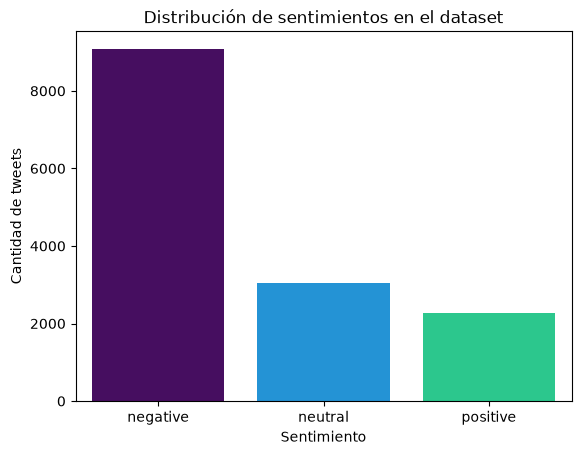

In [15]:
# Ordenar los sentimientos por cantidad de tweets, de mayor a menor
orden_sentimientos = data["airline_sentiment"].value_counts().index

sns.countplot(
    data=data,
    x="airline_sentiment",
    hue="airline_sentiment",
    order=orden_sentimientos,
    hue_order=orden_sentimientos,
    palette=[MORADO, AZUL, VERDE],
    legend=False
)

plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de tweets")
plt.title("Distribución de sentimientos en el dataset")
plt.show()

Observamos que existe un desbalance importante entre las clases de sentimiento. Hay una mayor cantidad de tweets clasificados como negativos, mientras que los tweets neutrales y positivos aparecen con menor frecuencia.

Esto debe tenerse en cuenta durante el entrenamiento del modelo, ya que podría tender a clasificar una mayor cantidad de tweets como negativos por ser la clase más frecuente. Por esta razón, será importante realizar una división estratificada de los datos y evaluar el desempeño del modelo para cada sentimiento, no solamente su exactitud general.

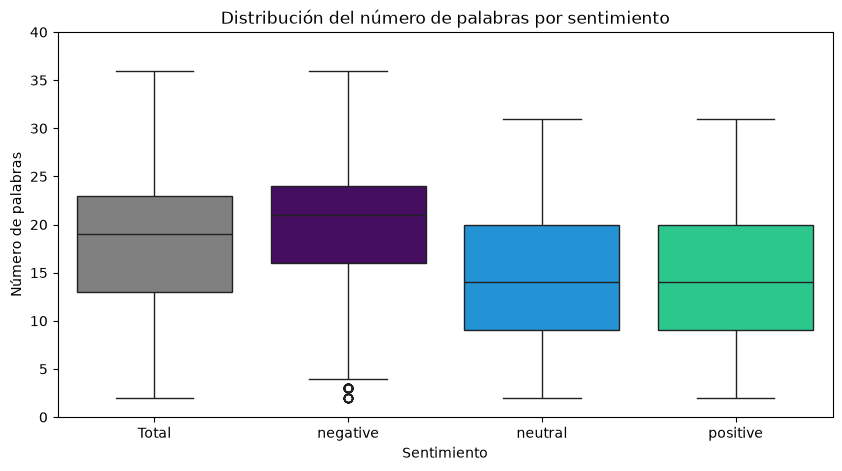

In [ ]:
# Calcular el número de palabras de cada tweet
numero_palabras = data["text"].str.split().str.len()

# Crear los datos para la categoría Total y por cada sentimiento
total = pd.DataFrame({"grupo": "Total", "numero_palabras": numero_palabras})
por_sentimiento = pd.DataFrame({"grupo": data["airline_sentiment"], "numero_palabras": numero_palabras})

# Unir ambas distribuciones
datos_grafica = pd.concat([total, por_sentimiento], ignore_index=True)

orden_grupos = ["Total", "negative", "neutral", "positive"]

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=datos_grafica,
    x="grupo",
    y="numero_palabras",
    hue="grupo",
    order=orden_grupos,
    hue_order=orden_grupos,
    palette=["gray", MORADO, AZUL, VERDE],
    legend=False
)

plt.xlabel("Sentimiento")
plt.ylabel("Número de palabras")
plt.title("Distribución del número de palabras por sentimiento")

plt.ylim(0, 40)
plt.yticks(range(0, 41, 5))

plt.show()

Todos los tweets contienen al menos dos palabras y el tweet más largo tiene aproximadamente 36 palabras. En general, las longitudes de los textos de las tres clases se superponen en gran medida.

Sin embargo, los tweets negativos tienden a ser un poco más largos: su mediana se encuentra alrededor de 21 palabras, mientras que las muestras neutrales y positivas tienen una mediana cercana a 14 palabras. Aun así, la longitud de los tweets por sí sola no parece ser suficiente para determinar el sentimiento, ya que las tres distribuciones cubren un rango amplio y similar de longitudes, lo que es positivo, ya que la longitud de los tweets no debería ser un factor determinante para la clasificación de sentimientos.

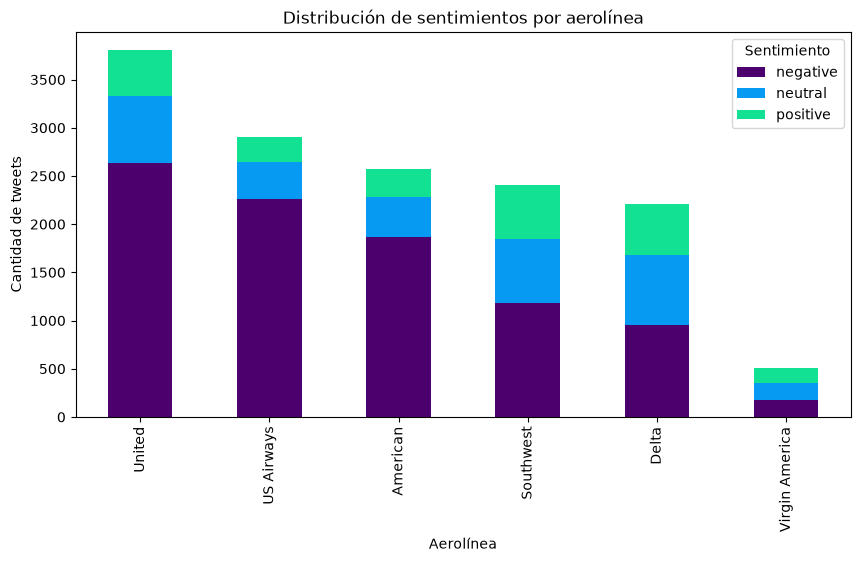

In [17]:
# Ordenar las aerolíneas por cantidad de tweets, de mayor a menor
orden_aerolineas = data["airline"].value_counts().index

# Contar los sentimientos de cada aerolínea
conteos_por_aerolinea = pd.crosstab(data["airline"], data["airline_sentiment"])
conteos_por_aerolinea = conteos_por_aerolinea.reindex(index=orden_aerolineas, columns=["negative", "neutral", "positive"])

conteos_por_aerolinea.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=[MORADO, AZUL, VERDE]
)

plt.xlabel("Aerolínea")
plt.ylabel("Cantidad de tweets")
plt.title("Distribución de sentimientos por aerolínea")
plt.legend(title="Sentimiento")

plt.show()

Observamos que también existe un desbalance en la cantidad de tweets asociados a cada aerolínea. United concentra la mayor cantidad de comentarios, mientras que Virgin America tiene la menor cantidad de muestras.

Además, las proporciones de sentimientos cambian entre aerolíneas. Por ejemplo, en US Airways predominan claramente los tweets negativos, mientras que Virgin America presenta una distribución más equilibrada entre las tres clases. Esto podría introducir un sesgo en el modelo, ya que el nombre de una aerolínea podría asociarse directamente con un sentimiento determinado.

Por esta razón, durante el preprocesamiento del texto buscaremos eliminar o normalizar las referencias a las aerolíneas, de manera que el modelo aprenda a identificar el sentimiento a partir del contenido del tweet y no de la aerolínea mencionada.

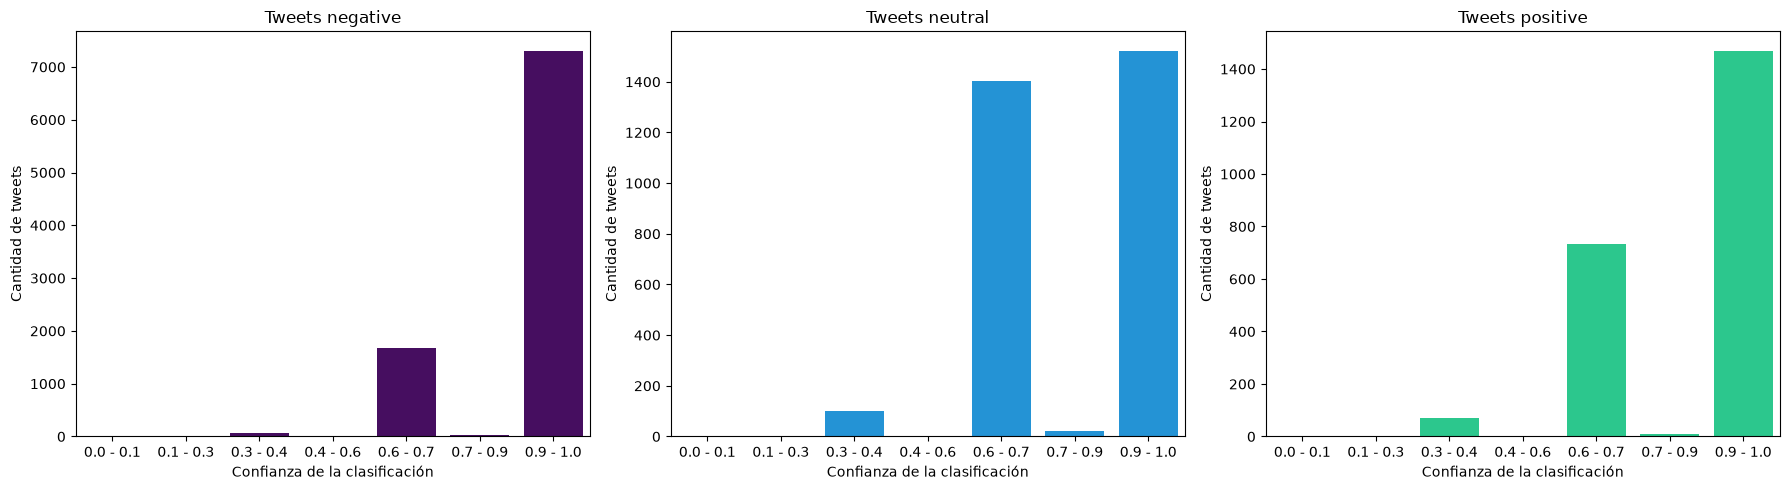

In [18]:
rangos = np.linspace(0, 1, 8)
etiquetas = [ f"{rangos[i]:.1f} - {rangos[i + 1]:.1f}" for i in range(len(rangos) - 1)]

def graficar_confianza(sentimiento, color, ax):
    # Seleccionar los tweets del sentimiento indicado
    tweets = data[data["airline_sentiment"] == sentimiento].copy()
    
    # Clasificar los valores de confianza en rangos
    tweets["rango_confianza"] = pd.cut(
        tweets["airline_sentiment_confidence"],
        bins=rangos,
        labels=etiquetas,
        include_lowest=True
    )
    
    sns.countplot(
        data=tweets,
        x="rango_confianza",
        order=etiquetas,
        color=color,
        ax=ax
    )
    
    ax.set_title(f"Tweets {sentimiento}")
    ax.set_xlabel("Confianza de la clasificación")
    ax.set_ylabel("Cantidad de tweets")


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

graficar_confianza("negative", MORADO, axes[0])
graficar_confianza("neutral", AZUL, axes[1])
graficar_confianza("positive", VERDE, axes[2])

plt.tight_layout()
plt.show()

En los tres sentimientos, la mayor cantidad de tweets se encuentra en el intervalo de confianza más alto. Esto indica que gran parte de las clasificaciones realizadas por los anotadores tiene un nivel de confianza elevado.

Sin embargo, los tweets neutrales presentan una proporción importante de observaciones en un intervalo de confianza intermedio. Esto sugiere que la clase neutral puede ser más difícil de identificar que las clases positiva y negativa, ya que algunos mensajes pueden contener expresiones ambiguas o poco claras. Sin embargo, el panorama no es crítico. 

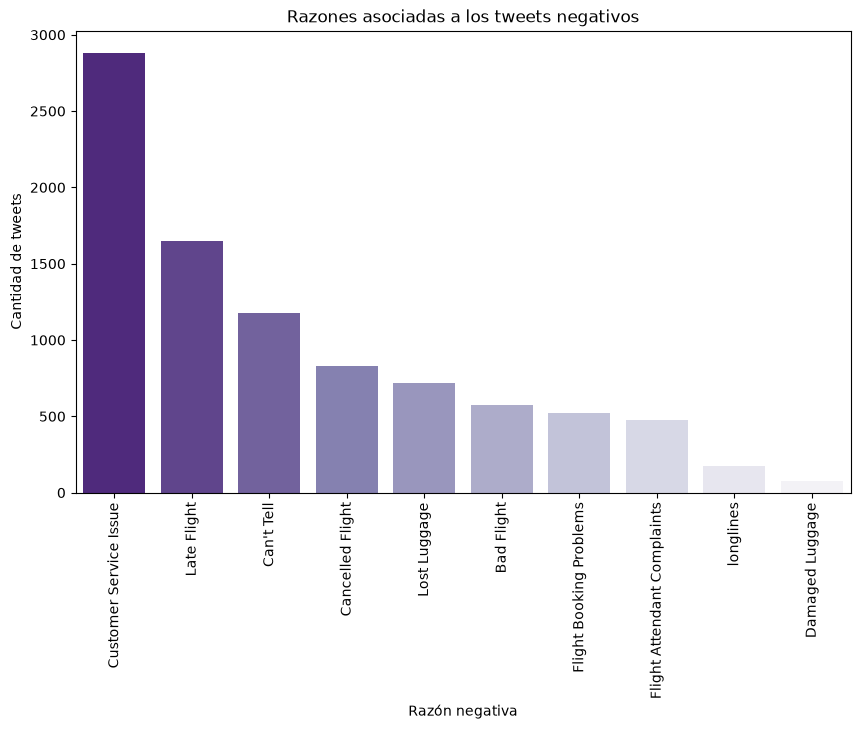

In [20]:
# Conservar únicamente los tweets clasificados como negativos
tweets_negativos = data[data["airline_sentiment"] == "negative"].copy()

# Ordenar las razones de mayor a menor frecuencia
orden_razones = (tweets_negativos["negativereason"].value_counts().index)


plt.figure(figsize=(10, 6))

sns.countplot(
    data=tweets_negativos,
    x="negativereason",
    hue="negativereason",
    order=orden_razones,
    hue_order=orden_razones,
    palette=sns.color_palette("Purples_r", n_colors=len(orden_razones)),
    legend=False
)

plt.ylabel("Cantidad de tweets")
plt.xticks(rotation=90)
plt.xlabel("Razón negativa")
plt.title("Razones asociadas a los tweets negativos")

plt.show()

La razón negativa más frecuente es `Customer Service Issue`, seguida por `Late Flight` y `Can't Tell`. Esto indica que una parte importante de los comentarios negativos del dataset está relacionada con problemas en la atención al cliente.

Por otro lado, algunas razones, como `Damaged Luggage` y `longlines`, tienen pocas muestras. Esto debe tenerse en cuenta al evaluar el modelo, ya que los casos poco representados pueden ser más difíciles de clasificar correctamente en escenarios reales.

## 3. Preprocesamiento del Texto y Vectorización de Tweets

Empezamos por dividir el dataset en conjuntos de entrenamiento, validación y prueba, procurando que la proporción de cada clase de sentimiento y de razón negativa se mantenga en cada conjunto.

In [32]:
# Combinar sentimiento y razón negativa para estratificar
estratos = (data["airline_sentiment"] + "_" + data["negativereason"].fillna("No reason"))
# print(estratos.value_counts())

# División del dataset en conjuntos de entrenamiento y test (80% - 20%)
entrenamiento, test = train_test_split(
    data,
    test_size=0.20,
    shuffle=True,
    random_state=SEED,
    stratify=estratos
)

# División del conjunto de entrenamiento en conjuntos de entrenamiento y validación (75% - 25%)
estratos_entrenamiento = (entrenamiento["airline_sentiment"] + "_" + entrenamiento["negativereason"].fillna("No reason"))
# print(estratos_entrenamiento.value_counts())

entrenamiento, validacion = train_test_split(
    entrenamiento,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 del total
    shuffle=True,
    random_state=SEED,
    stratify=estratos_entrenamiento
)

print(f"Entrenamiento: {len(entrenamiento)} registros")
print(f"Validación: {len(validacion)} registros")
print(f"Prueba: {len(test)} registros")

Entrenamiento: 8643 registros
Validación: 2881 registros
Prueba: 2882 registros


In [33]:
# Variables de entrada: texto de los tweets
x_train = entrenamiento["text"]
x_val = validacion["text"]
x_test = test["text"]

# Variables de salida: sentimiento.
codificacion_sentimiento = {"negative": 0, "neutral": 1, "positive": 2}

y_train = entrenamiento["airline_sentiment"].map(codificacion_sentimiento)
y_val = validacion["airline_sentiment"].map(codificacion_sentimiento)
y_test = test["airline_sentiment"].map(codificacion_sentimiento)

# Transformar las etiquetas de salida en vectores one-hot
y_train = keras.utils.to_categorical(y_train, num_classes=3)
y_val = keras.utils.to_categorical(y_val, num_classes=3)
y_test = keras.utils.to_categorical(y_test, num_classes=3)

print("Ejemplo de entrada (x_train):", x_train.iloc[0])
print("Ejemplo de salida (y_train):", y_train[0])

Ejemplo de entrada (x_train): @united since when did you get so good again!  4 transcontinental flights in 72h.  What a pleasure/relief you were.
Ejemplo de salida (y_train): [0. 0. 1.]
